# **Image Classification with a Convolutional Neural Network in PyTorch**

## **DSA4050 Assignment**

### **Name:** Claire Mwarari

### **Student ID:** 669470

In this notebook I build an image classifier in PyTorch. The dataset has 50,000 small colour images (32 x 32 pixels) and 10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck. Labels are given for 4,000 images in Train.csv. The goal is to predict the labels of the 46,000 images listed in Test.csv.

## Approach

1. **Data loading.** I write a custom data loader that subclasses `torch.utils.data.Dataset`. It reads the image id from the csv, opens the matching png file, and returns the image tensor together with its label.
2. **Augmentation.** Training images are augmented on the fly with random crops (32 pixels with 4 pixels of padding) and random horizontal flips. This makes the training set effectively larger and reduces overfitting, which matters because we only have 400 labeled images per class.
3. **Model.** A CNN in the style of the course notes: blocks of Conv2d, BatchNorm2d, ReLU and MaxPool2d, followed by fully connected layers with dropout.
4. **Hyper-parameter selection.** I use grid search: every combination of optimizer (Adam or SGD with momentum), learning rate and batch size is trained for 10 epochs, and the combination with the best validation accuracy wins.
5. **Final training and prediction.** The winning configuration is retrained on all 4,000 labeled images for 40 epochs, then used to predict the Test.csv images.

## 1. Get the data

In [1]:
# download the two zip files from Google Drive (takes a minute)
!pip -q install gdown
!gdown --fuzzy "https://drive.google.com/file/d/1hU98cHF6Lr6LRhXMroIwZ9v2xkNTKoPO/view?usp=sharing" -O train.zip
!gdown --fuzzy "https://drive.google.com/file/d/1iP6ysY7xBW1hWONBSgxVkujvJiGk_F0N/view?usp=sharing" -O Trial.zip

import zipfile, os
for f in ['train.zip', 'Trial.zip']:
    with zipfile.ZipFile(f) as z:
        z.extractall('data_raw')
print('extracted:', os.listdir('data_raw'))

Downloading...
From (original): https://drive.google.com/uc?id=1hU98cHF6Lr6LRhXMroIwZ9v2xkNTKoPO
From (redirected): https://drive.google.com/uc?id=1hU98cHF6Lr6LRhXMroIwZ9v2xkNTKoPO&confirm=t&uuid=d4d01941-a7b3-4b3a-9c0f-ce17faa81d62
To: /content/train.zip
100% 121M/121M [00:04<00:00, 26.7MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1iP6ysY7xBW1hWONBSgxVkujvJiGk_F0N
From (redirected): https://drive.google.com/uc?id=1iP6ysY7xBW1hWONBSgxVkujvJiGk_F0N&confirm=t&uuid=4ec9cba8-4c5a-4082-8fc1-d18f38e193df
To: /content/Trial.zip
100% 123M/123M [00:02<00:00, 43.1MB/s]
extracted: ['train', 'Trial']


In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('using device:', device)

using device: cuda


In [3]:
# find the csv files and the image folder no matter how the zips were structured
csv_train = csv_test = img_dir = None
for root, dirs, files in os.walk('data_raw'):
    for f in files:
        if f == 'Train.csv':
            csv_train = os.path.join(root, f)
        if f == 'Test.csv':
            csv_test = os.path.join(root, f)
    if 'train' in dirs:
        img_dir = os.path.join(root, 'train')

train_csv = pd.read_csv(csv_train)
test_csv = pd.read_csv(csv_test)
print('Train.csv:', train_csv.shape)
print('Test.csv:', test_csv.shape)
print('images in folder:', len(os.listdir(img_dir)))
train_csv.head()

Train.csv: (4000, 2)
Test.csv: (46000, 2)
images in folder: 50000


,id,label
0,44011,truck
1,40500,deer
2,19479,horse
3,3682,ship
4,7367,ship


['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


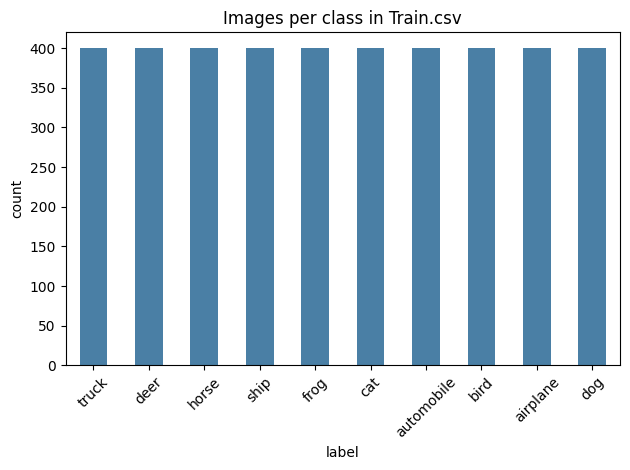

In [4]:
classes = sorted(train_csv['label'].unique())
cls2idx = {c: i for i, c in enumerate(classes)}
print(classes)

# class distribution
train_csv['label'].value_counts().plot(kind='bar', color='#4a7fa5')
plt.title('Images per class in Train.csv')
plt.ylabel('count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

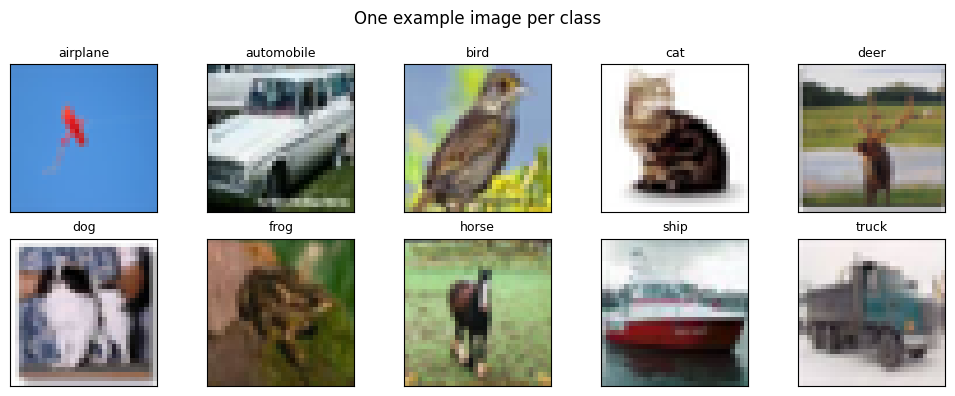

In [5]:
# look at a few example images
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for c, ax in zip(classes, axes.flat):
    img_id = train_csv[train_csv['label'] == c]['id'].iloc[0]
    ax.imshow(Image.open(os.path.join(img_dir, f'{img_id}.png')))
    ax.set_title(c, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('One example image per class')
fig.tight_layout()
plt.show()

## 2. Custom data loader with augmentation

The dataset class below subclasses `torch.utils.data.Dataset`, as required. It keeps a reference to the csv dataframe and the image folder. In `__getitem__` it opens the image for the given id, applies the transform, and returns the image with its label. For the test csv there are no labels, so it returns the id instead.

For training data the transform includes **random cropping with padding** and **random horizontal flipping**. Both create slightly different versions of the training images every epoch, so the model sees more variety and memorizes less. `ToTensor()` also scales the pixel values to [0, 1], which helps optimization.

In [6]:
train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])
eval_tf = transforms.ToTensor()  # no augmentation for validation and test data


class ImageDataset(Dataset):
    """Custom dataset: reads image files by id and looks up labels in the csv."""

    def __init__(self, df, img_dir, transform=None, has_labels=True):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
        self.has_labels = has_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(self.img_dir, f"{int(row['id'])}.png")).convert('RGB')
        if self.transform:
            img = self.transform(img)
        if self.has_labels:
            return img, cls2idx[row['label']]
        return img, row['id']


# quick check
sample = ImageDataset(train_csv, img_dir, train_tf)
img, label = sample[0]
print('image tensor:', img.shape, '| label:', label, '=', classes[label])

image tensor: torch.Size([3, 32, 32]) | label: 9 = truck


## 3. The CNN model

A plain neural network would flatten the image and lose the spatial layout of the pixels. A CNN instead slides small filters over the image to extract local features, and pooling reduces the size of the feature maps. The architecture follows the pattern from the course notes: repeated blocks of Conv2d, BatchNorm2d, ReLU and MaxPool2d, then fully connected layers with dropout for the final classification into 10 classes.

In [7]:
class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.cnn_layers = nn.Sequential(
            # block 1: 32x32 -> 16x16
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            # block 2: 16x16 -> 8x8
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            # block 3: 8x8 -> 4x4
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
        self.linear_layers = nn.Sequential(
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.cnn_layers(x)
        x = x.view(x.size(0), -1)
        return self.linear_layers(x)


print(CNN())

CNN(
  (cnn_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, c

In [8]:
def train_model(model, train_loader, val_loader, optimizer, epochs, verbose=True):
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    for ep in range(epochs):
        model.train()
        total, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()          # clear old gradients
            output = model(xb)             # forward pass
            loss = criterion(output, yb)   # compute the loss
            loss.backward()                # backward pass
            optimizer.step()               # update the weights
            total += loss.item() * len(yb)
            n += len(yb)
        history['train_loss'].append(total / n)

        model.eval()
        vtotal, vn, correct = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                output = model(xb)
                vtotal += criterion(output, yb).item() * len(yb)
                vn += len(yb)
                correct += (output.argmax(1) == yb).sum().item()
        history['val_loss'].append(vtotal / vn)
        history['val_acc'].append(correct / vn)
        if verbose:
            print(f'epoch {ep+1}/{epochs}  train_loss={history["train_loss"][-1]:.4f}  '
                  f'val_loss={history["val_loss"][-1]:.4f}  val_acc={history["val_acc"][-1]:.4f}')
    return history

## 4. Hyper-parameter selection with grid search

I keep 20% of the labeled images (800 images) aside as a validation set. Then I run **grid search**: every combination of the three hyper-parameters below is trained for 10 epochs, and the validation accuracy decides the winner.

* optimizer: Adam or SGD with momentum 0.9
* learning rate: 0.001 or 0.0005 for Adam, 0.01 or 0.05 for SGD
* batch size: 32 or 64

Grid search is simple and guarantees that every combination in the grid is tried, which is appropriate here because the grid is small and each training run is short.

In [9]:
tr_df, va_df = train_test_split(train_csv, test_size=0.20,
                                stratify=train_csv['label'], random_state=SEED)
print('train:', len(tr_df), 'validation:', len(va_df))

grid = []
for opt_name in ['adam', 'sgd_momentum']:
    for lr in ([0.001, 0.0005] if opt_name == 'adam' else [0.01, 0.05]):
        for bs in [32, 64]:
            grid.append({'optimizer': opt_name, 'lr': lr, 'batch_size': bs})

grid_results = []
for cfg in grid:
    train_loader = DataLoader(ImageDataset(tr_df, img_dir, train_tf),
                              batch_size=cfg['batch_size'], shuffle=True)
    val_loader = DataLoader(ImageDataset(va_df, img_dir, eval_tf), batch_size=256)
    torch.manual_seed(SEED)
    model = CNN().to(device)
    if cfg['optimizer'] == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=cfg['lr'])
    else:
        optimizer = optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9)
    hist = train_model(model, train_loader, val_loader, optimizer, epochs=10, verbose=False)
    best_val = max(hist['val_acc'])
    grid_results.append({**cfg, 'best_val_acc': best_val})
    print(cfg, '-> best validation accuracy:', round(best_val, 4))

grid_df = pd.DataFrame(grid_results).sort_values('best_val_acc', ascending=False)
grid_df

train: 3200 validation: 800
{'optimizer': 'adam', 'lr': 0.001, 'batch_size': 32} -> best validation accuracy: 0.475
{'optimizer': 'adam', 'lr': 0.001, 'batch_size': 64} -> best validation accuracy: 0.5212
{'optimizer': 'adam', 'lr': 0.0005, 'batch_size': 32} -> best validation accuracy: 0.55
{'optimizer': 'adam', 'lr': 0.0005, 'batch_size': 64} -> best validation accuracy: 0.5175
{'optimizer': 'sgd_momentum', 'lr': 0.01, 'batch_size': 32} -> best validation accuracy: 0.375
{'optimizer': 'sgd_momentum', 'lr': 0.01, 'batch_size': 64} -> best validation accuracy: 0.4175
{'optimizer': 'sgd_momentum', 'lr': 0.05, 'batch_size': 32} -> best validation accuracy: 0.1113
{'optimizer': 'sgd_momentum', 'lr': 0.05, 'batch_size': 64} -> best validation accuracy: 0.2662


,optimizer,lr,batch_size,best_val_acc
2,adam,0.0005,32,0.55000
1,adam,0.0010,64,0.52125
3,adam,0.0005,64,0.51750
0,adam,0.0010,32,0.47500
5,sgd_momentum,0.0100,64,0.41750
4,sgd_momentum,0.0100,32,0.37500
7,sgd_momentum,0.0500,64,0.26625
6,sgd_momentum,0.0500,32,0.11125


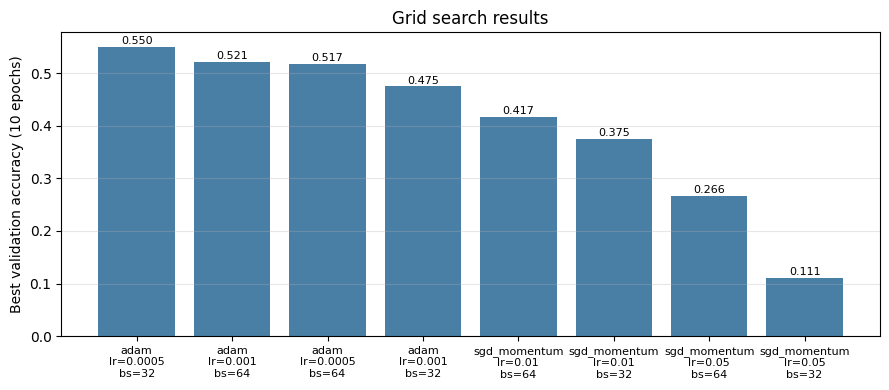

best configuration: {'optimizer': 'adam', 'lr': 0.0005, 'batch_size': 32, 'best_val_acc': 0.55}


In [10]:
# plot the grid search results
labels = [f"{r['optimizer']}\nlr={r['lr']}\nbs={r['batch_size']}" for _, r in grid_df.iterrows()]
plt.figure(figsize=(9, 4))
bars = plt.bar(range(len(grid_df)), grid_df['best_val_acc'], color='#4a7fa5')
for b, v in zip(bars, grid_df['best_val_acc']):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f'{v:.3f}', ha='center', fontsize=8)
plt.xticks(range(len(grid_df)), labels, fontsize=8)
plt.ylabel('Best validation accuracy (10 epochs)')
plt.title('Grid search results')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

best_cfg = grid_df.iloc[0].to_dict()
best_cfg['batch_size'] = int(best_cfg['batch_size'])
print('best configuration:', best_cfg)

## 5. Final model

The winning configuration is now retrained on **all** 4,000 labeled images (the validation split is no longer needed because the hyper-parameters are fixed). Training runs for 40 epochs with augmentation on.

In [11]:
torch.manual_seed(SEED)
full_loader = DataLoader(ImageDataset(train_csv, img_dir, train_tf),
                         batch_size=best_cfg['batch_size'], shuffle=True)
val_loader = DataLoader(ImageDataset(va_df, img_dir, eval_tf), batch_size=256)

final_model = CNN().to(device)
if best_cfg['optimizer'] == 'adam':
    optimizer = optim.Adam(final_model.parameters(), lr=best_cfg['lr'])
else:
    optimizer = optim.SGD(final_model.parameters(), lr=best_cfg['lr'], momentum=0.9)

history = train_model(final_model, full_loader, val_loader, optimizer, epochs=40)

epoch 1/40  train_loss=2.0173  val_loss=1.6745  val_acc=0.3575
epoch 2/40  train_loss=1.7441  val_loss=1.6262  val_acc=0.3825
epoch 3/40  train_loss=1.6138  val_loss=1.3976  val_acc=0.4600
epoch 4/40  train_loss=1.5470  val_loss=1.4365  val_acc=0.4637
epoch 5/40  train_loss=1.4657  val_loss=1.2774  val_acc=0.5112
epoch 6/40  train_loss=1.4273  val_loss=1.2640  val_acc=0.5312
epoch 7/40  train_loss=1.3729  val_loss=1.2503  val_acc=0.5425
epoch 8/40  train_loss=1.3149  val_loss=1.1357  val_acc=0.5938
epoch 9/40  train_loss=1.2838  val_loss=1.1454  val_acc=0.5813
epoch 10/40  train_loss=1.2510  val_loss=1.0722  val_acc=0.6000
epoch 11/40  train_loss=1.2189  val_loss=1.0500  val_acc=0.6275
epoch 12/40  train_loss=1.1935  val_loss=1.0277  val_acc=0.6200
epoch 13/40  train_loss=1.1584  val_loss=1.0104  val_acc=0.6412
epoch 14/40  train_loss=1.1328  val_loss=0.9750  val_acc=0.6450
epoch 15/40  train_loss=1.0908  val_loss=0.8914  val_acc=0.6775
epoch 16/40  train_loss=1.0722  val_loss=0.9077  

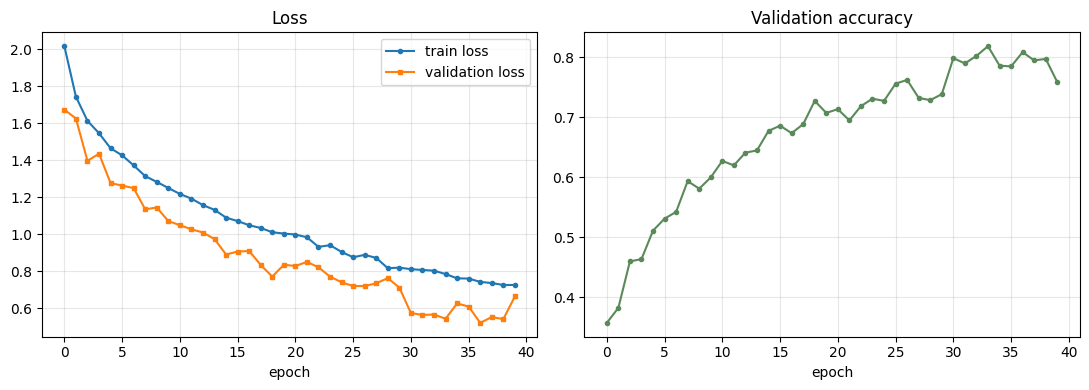

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history['train_loss'], marker='o', ms=3, label='train loss')
ax[0].plot(history['val_loss'], marker='s', ms=3, label='validation loss')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(history['val_acc'], marker='o', ms=3, color='#5a8a5a')
ax[1].set_title('Validation accuracy'); ax[1].set_xlabel('epoch'); ax[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 6. Predicting the test set and the submission csv

The final model predicts all 46,000 images from Test.csv. The predictions are merged back onto the original Test.csv order, so the submission file has exactly the same rows, with the label column filled in.

In [13]:
test_loader = DataLoader(ImageDataset(test_csv, img_dir, eval_tf, has_labels=False),
                         batch_size=256)
final_model.eval()
preds, ids = [], []
with torch.no_grad():
    for xb, batch_ids in test_loader:
        out = final_model(xb.to(device))
        preds.append(out.argmax(1).cpu().numpy())
        ids.extend(batch_ids.numpy().tolist())

pred_df = pd.DataFrame({'id': ids, 'label': [classes[p] for p in np.concatenate(preds)]})
submission = test_csv[['id']].merge(pred_df, on='id', how='left')
assert len(submission) == len(test_csv) and submission['label'].notna().all()
submission.to_csv('submission.csv', index=False)
print('submission.csv written:', submission.shape)
submission.head(10)

submission.csv written: (46000, 2)


,id,label
0,33680,truck
1,24631,deer
2,34739,cat
3,15922,truck
4,44282,airplane
5,7754,horse
6,44017,horse
7,25147,cat
8,8224,dog
9,8068,cat


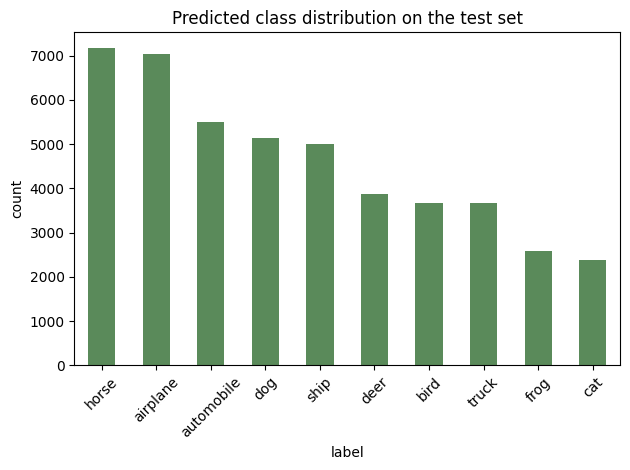

In [14]:
# prediction distribution across classes
submission['label'].value_counts().plot(kind='bar', color='#5a8a5a')
plt.title('Predicted class distribution on the test set')
plt.ylabel('count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# download the submission file
from google.colab import files
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>